dimensional

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

L = 3.0
H = 1.0
nx = 150
ny = 100
dx = L / (nx - 1)
dy = H / (ny - 1)

dt = 0.001
nt = 5001
nit = 200

In [ ]:
x = np.linspace(0, L, nx)
y = np.linspace(0, H, ny)
X, Y = np.meshgrid(x, y)

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
omega_z = np.zeros((ny, nx))

obstacle = (X - 0.5)**2 + (Y - 0.5)**2 < 0.2**2
obstacle1 = (X - 2.0)**2 + (Y - 0.8)**2 < 0.2**2

mask = np.ones((ny, nx))
mask[obstacle] = 0.0
mask[obstacle1] = 0.0

def apply_velocity_bc(u, v):
    
    u[:, 0] = 1.0
    v[:, 0] = 0.0

    u[:, -1] = u[:, -2]
    v[:, -1] = v[:, -2]
    
    u[0, :] = 0.0
    u[-1, :] = 0.0
    v[0, :] = 0.0
    v[-1, :] = 0.0

    u[obstacle] = 0.0
    v[obstacle] = 0.0
    u[obstacle1] = 0.0
    v[obstacle1] = 0.0
    
    return u, v

def apply_pressure_bc(p):
    
    p[0, :] = p[1, :]
    p[-1, :] = p[-2, :]

    p[:, 0] = p[:, 1]

    p[:, -1] = 0.0
    
    return p

def solve_pressure(p, u, v, dx, dy, dt, nit):

    b = np.zeros_like(p)
    b[1:-1, 1:-1] = (1 / dt) * (
        (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
        (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    )
    
    b[obstacle] = 0.0
    b[obstacle1] = 0.0

    omega_z[1:-1, 1:-1] = (
        (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx) -   # ∂v/∂x 
        (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)     # ∂u/∂y
        )

    omega_z[obstacle] = 0.0
    omega_z[obstacle1] = 0.0

    for _ in range(nit):
        p_old = p.copy()

        p[1:-1, 1:-1] = (
            (p[1:-1, 2:] + p[1:-1, :-2]) * dy**2 +
            (p[2:, 1:-1] + p[:-2, 1:-1]) * dx**2 -
            b[1:-1, 1:-1] * dx**2 * dy**2
        ) / (2 * (dx**2 + dy**2))
        
        p[obstacle] = 0.0
        p[obstacle1] = 0.0

        p = apply_pressure_bc(p)
    
    return p, omega_z

def predict_velocity(u, v, dx, dy, dt, Re):

    u_star = u.copy()
    v_star = v.copy()
    
    # Advection terms
    du_dx = (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
    du_dy = (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
    dv_dx = (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx)
    dv_dy = (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    
    # Diffusion terms
    d2u_dx2 = (u[1:-1, 2:] - 2*u[1:-1, 1:-1] + u[1:-1, :-2]) / dx**2
    d2u_dy2 = (u[2:, 1:-1] - 2*u[1:-1, 1:-1] + u[:-2, 1:-1]) / dy**2
    d2v_dx2 = (v[1:-1, 2:] - 2*v[1:-1, 1:-1] + v[1:-1, :-2]) / dx**2
    d2v_dy2 = (v[2:, 1:-1] - 2*v[1:-1, 1:-1] + v[:-2, 1:-1]) / dy**2
    
    # Intermediate velocity
    u_star[1:-1, 1:-1] = (
        u[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
        + dt * (1/Re) * (d2u_dx2 + d2u_dy2)
    )
    v_star[1:-1, 1:-1] = (
        v[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
        + dt * (1/Re) * (d2v_dx2 + d2v_dy2)
    )

    u_star[obstacle] = 0.0 ; u_star[obstacle1] = 0.0
    v_star[obstacle] = 0.0 ; v_star[obstacle1] = 0.0
    
    return u_star, v_star

def correct_velocity(u_star, v_star, p, dx, dy, dt):

    u_new = u_star.copy()
    v_new = v_star.copy()
    
    dp_dx = (p[1:-1, 2:] - p[1:-1, :-2]) / (2 * dx)
    dp_dy = (p[2:, 1:-1] - p[:-2, 1:-1]) / (2 * dy)
    
    u_new[1:-1, 1:-1] = u_star[1:-1, 1:-1] - (dt) * dp_dx
    v_new[1:-1, 1:-1] = v_star[1:-1, 1:-1] - (dt) * dp_dy
    
    u_new[obstacle] = 0.0 ; u_new[obstacle1] = 0.0
    v_new[obstacle] = 0.0 ; v_new[obstacle1] = 0.0
    
    return u_new, v_new


In [8]:
import numpy as np
import matplotlib.pyplot as plt

Re_list = np.arange(0, 825, 25) 
ts = 5001

Re_result = []
u_max = []
v_max = []

for Re in Re_list:
    print(f"Re = {Re}...")

    u = np.zeros((ny, nx))
    v = np.zeros((ny, nx))
    p = np.zeros((ny, nx))
    omega_z = np.zeros((ny, nx))
    
    exploded = False
    
    for n in range(ts):
        u, v = apply_velocity_bc(u, v)
        u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
        p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
        u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
        u, v = apply_velocity_bc(u, v)
        
        if np.isnan(u).any() or np.isnan(v).any():
            print(f"u exploded at ts {n}.")
            exploded = True
            break

    Re_result.append(Re)
    
    if not exploded:
        u_max_rn = np.max(np.abs(u))
        u_max.append(u_max_rn)
        v_max_rn = np.max(np.abs(v))
        v_max.append(v_max_rn)
    else:
        u_max.append(np.nan)
        v_max.append(np.nan)



Re = 0...
u exploded at ts 0.
Re = 25...


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:109: RuntimeWarning: divide by zero encountered in scalar divide
  + dt * (1/Re) * (d2u_dx2 + d2u_dy2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:109: RuntimeWarning: invalid value encountered in multiply
  + dt * (1/Re) * (d2u_dx2 + d2u_dy2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:114: RuntimeWarning: divide by zero encountered in scalar divide
  + dt * (1/Re) * (d2v_dx2 + d2v_dy2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:114: RuntimeWarning: invalid value encountered in multiply
  + dt * (1/Re) * (d2v_dx2 + d2v_dy2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:66: RuntimeWarning: invalid value encountered in subtract
  (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)     # ∂u/∂y


Re = 50...
Re = 75...
Re = 100...
Re = 125...
Re = 150...
Re = 175...
Re = 200...
Re = 225...
Re = 250...
Re = 275...
Re = 300...
Re = 325...
Re = 350...
Re = 375...
Re = 400...
Re = 425...
Re = 450...
Re = 475...
Re = 500...
Re = 525...
Re = 550...
Re = 575...
Re = 600...
Re = 625...
Re = 650...
Re = 675...
Re = 700...
Re = 725...
Re = 750...
Re = 775...


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: invalid value encountered in s

u exploded at ts 500.
Re = 800...
u exploded at ts 440.


In [9]:
import pandas as pd 

df = pd.DataFrame({'u':u_max,
                   'v':v_max})
df.to_csv('uv_max_fixxxxxxxxxx.txt')

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\2477480830.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


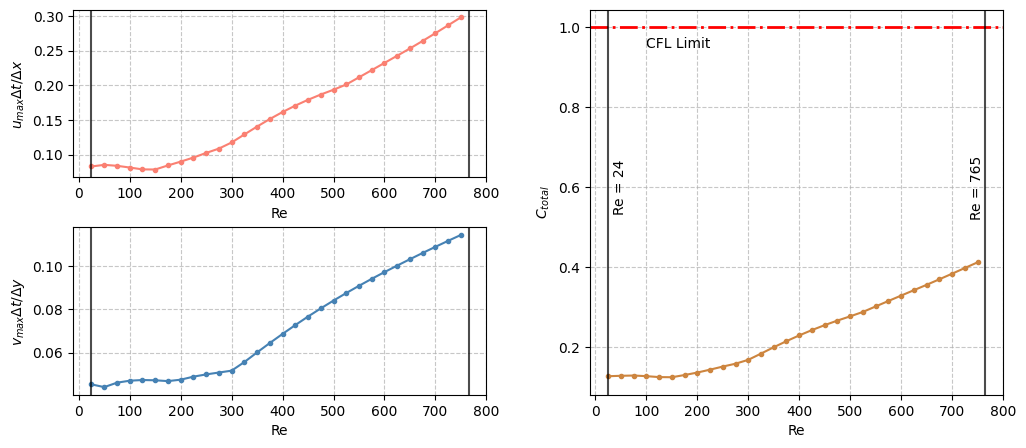

In [40]:
import numpy as np
import matplotlib.pyplot as plt

u_max_arr = np.array(u_max)
v_max_arr = np.array(v_max)
Re_arr = np.array(Re_result)

u_dof = u_max_arr * (dt / dx) 
v_dof = v_max_arr * (dt / dy)
C = u_dof + v_dof

fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1], wspace=0.25, hspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

ax1.plot(Re_arr, u_dof, marker='.', linestyle='-', color='salmon')
ax1.set_xlabel('Re', fontsize=10)
ax1.set_ylabel(r'$u_{max} \Delta t / \Delta x$', fontsize=10)
ax1.axvline(x=24, color='k', linestyle='-', alpha=0.7)
ax1.axvline(x=765, color='k', linestyle='-', alpha=0.7)
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(Re_arr, v_dof, marker='.', linestyle='-', color='steelblue')
ax2.set_xlabel('Re', fontsize=10)
ax2.set_ylabel(r'$v_{max} \Delta t / \Delta y$', fontsize=10)
ax2.axvline(x=24, color='k', linestyle='-', alpha=0.7)
ax2.axvline(x=765, color='k', linestyle='-', alpha=0.7)
ax2.grid(True, linestyle='--', alpha=0.7)

ax3.plot(Re_arr, C, marker='.', linestyle='-', color='peru')
ax3.axhline(y=1.0, color='r', linestyle='-.', linewidth=2)
ax3.axvline(x=24, color='k', linestyle='-', alpha=0.7)
ax3.axvline(x=765, color='k', linestyle='-', alpha=0.7)
ax3.text(100, 0.95, 'CFL Limit', color='black', 
         fontsize=10)
ax3.text(35, 0.6, 'Re = 24', color='k', 
         fontsize=10, rotation=90, va='center')
ax3.text(735, 0.6, 'Re = 765', color='k', 
         fontsize=10, rotation=90, va='center')
ax3.set_xlabel('Re', fontsize=10)
ax3.set_ylabel(r'$C_{total}$', fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.7)



for ax in [ax1, ax2, ax3]:
    ax.set_xticks(np.arange(0, 850, 100))
    ax.set_xticklabels([str(int(x)) for x in ax.get_xticks()]) 
    
plt.tight_layout()
plt.show()

In [54]:
Re = 24
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
value = {}
nt_764 = 5001

for n in range(nt_764):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)
    

    
    if n in [470, 475, 480, 485]:
        value[n] = (u.copy(), v.copy()) 


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:56: RuntimeWarning: invalid value encountered in subtract
  (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:57: RuntimeWarning: invalid value encountered in subtrac

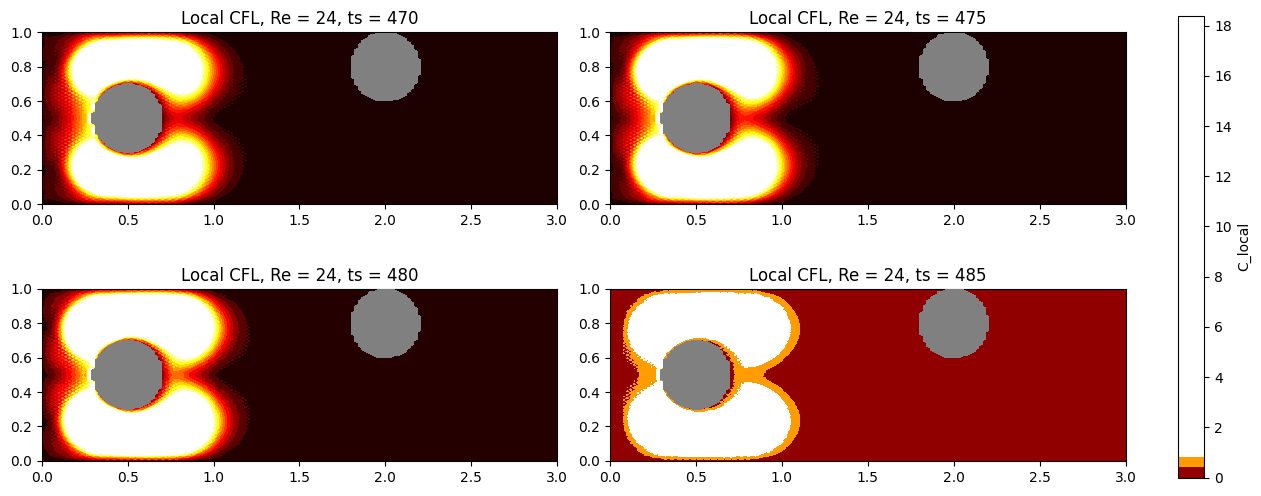

In [55]:
import matplotlib.pyplot as plt
import numpy as np

plot_steps = [470, 475, 480, 485]

fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.05], wspace=0.15, hspace=0.25)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])
cbar_ax = fig.add_subplot(gs[:, 2])

axes = [ax1, ax2, ax3, ax4]

for idx, step in enumerate(plot_steps):

    u, v = value[step]
    C_field = np.abs(u) * (dt / dx) + np.abs(v) * (dt / dy)
    
    ax = axes[idx]
    cf = ax.contourf(X, Y, C_field, levels=50, cmap='hot', vmin=0, vmax=1.0)
    ax.contourf(X, Y, obstacle, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=4)
    
    ax.set_title(f'Local CFL, Re = {Re}, ts = {step}')
    ax.set_aspect('equal')

cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('C_local', fontsize=10)

plt.show()


In [41]:

Re = 24
u_765 = []
v_765 = []

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
omega_z = np.zeros((ny, nx))
    
exploded = False
    
for n in range(nt):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)

    if np.isnan(u).any() or np.isnan(v).any():
        print(f"u exploded at ts {n}.")
        exploded = True
        break

    if not exploded:
        u_765_rn = np.max(np.abs(u))
        u_765.append(u_765_rn)
        v_765_rn = np.max(np.abs(v))
        v_765.append(v_765_rn)
    else:
        u_765.append(np.nan)
        v_765.append(np.nan)



u exploded at ts 496.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:56: RuntimeWarning: invalid value encountered in subtract
  (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:57: RuntimeWarning: invalid value encountered in subtrac

In [99]:

Re = 24 
u_lim_2 = []
v_lim_2 = []

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
omega_z = np.zeros((ny, nx))

nt_lim = 617
    
exploded = False
    
for n in range(nt_lim):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)
    
    if np.isnan(u).any() or np.isnan(v).any():
        exploded = True
        break
    if not exploded:
        if n in [420, 422, 424, 426, 428, 430,  
                 432, 434, 436, 438, 440, 442,
                 444, 446, 448, 450, 452, 454,  
                 456, 458, 460, 462, 464, 466]:
            u_lim_rn = np.max(np.abs(u))
            u_lim_2.append(u_lim_rn)
            v_lim_rn = np.max(np.abs(v))
            v_lim_2.append(v_lim_rn)
    else:
        u_lim_2.append(np.nan)
        v_lim_2.append(np.nan)



C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:56: RuntimeWarning: invalid value encountered in subtract
  (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:57: RuntimeWarning: invalid value encountered in subtrac

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\3883686858.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


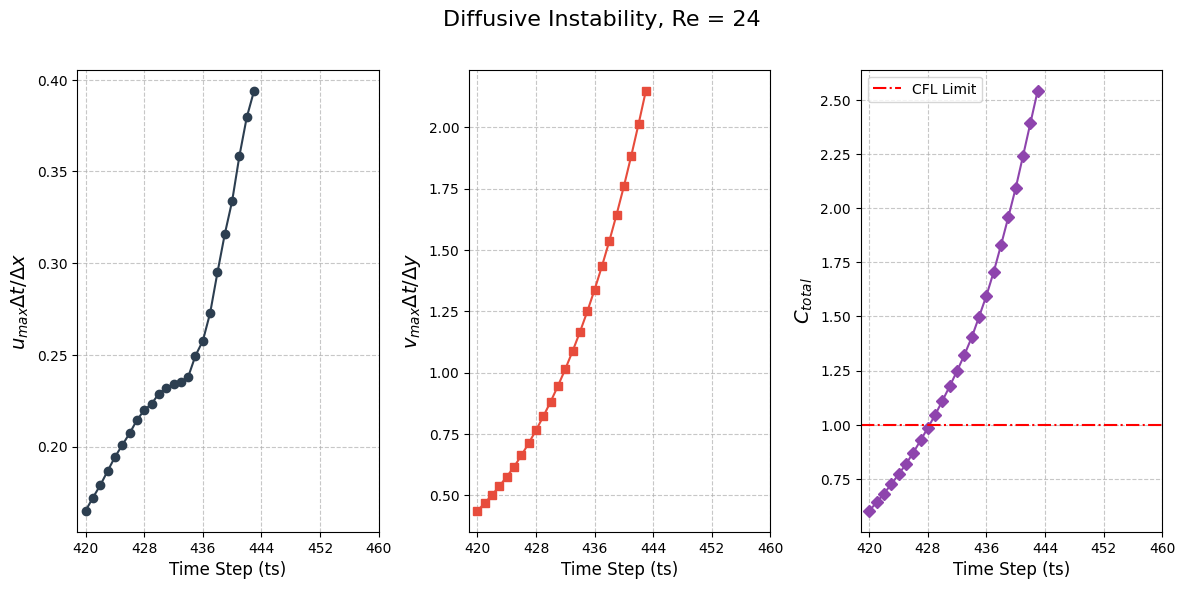

In [101]:
import matplotlib.pyplot as plt
import numpy as np

u_max_arr = np.array(u_lim_2)
v_max_arr = np.array(v_lim_2)
u_dof = u_max_arr * (dt / dx) 
v_dof = v_max_arr * (dt / dy)

ts_arr = np.arange(420, 420 + len(u_max_arr), 1) 
C = u_dof + v_dof

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 3, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

ax1.plot(ts_arr, u_max_arr * (dt / dx), marker='o', linestyle='-', color='#2c3e50')
ax1.set_xlabel('Time Step (ts)', fontsize=12)
ax1.set_ylabel(r'$u_{max} \Delta t / \Delta x$', fontsize=14)
#ax1.set_yscale('log')
ax1.grid(True, linestyle='--', alpha=0.7, which='both')

ax2.plot(ts_arr, v_max_arr * (dt / dy), marker='s', linestyle='-', color='#e74c3c')
ax2.set_xlabel('Time Step (ts)', fontsize=12)
ax2.set_ylabel(r'$v_{max} \Delta t / \Delta y$', fontsize=14)
#ax2.set_yscale('log')
ax2.grid(True, linestyle='--', alpha=0.7, which='both')

ax3.plot(ts_arr, C, marker='D', linestyle='-', color='#8e44ad')
ax3.axhline(y=1.0, color='r', linestyle='-.', label='CFL Limit')
ax3.set_xlabel('Time Step (ts)', fontsize=12)
ax3.set_ylabel(r'$C_{total}$', fontsize=14)
#ax3.set_yscale('log')
ax3.grid(True, linestyle='--', alpha=0.7, which='both')
ax3.legend(loc='upper left')

for ax in [ax1, ax2, ax3]:
    ax.set_xticks(np.arange(420, 466, 8))
    ax.set_xticklabels([str(int(x)) for x in ax.get_xticks()]) 

fig.suptitle('Diffusive Instability, Re = 24', fontsize=16)
plt.tight_layout()
plt.show()

In [96]:
Re = 24
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
value = {}
nt_765 = 490

for n in range(nt_765):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)
    
    if n in [422, 424, 428, 
             442, 444, 448, 
             462, 464, 468, 
             484, 485, 486]:
        value[n] = (u.copy(), v.copy()) 


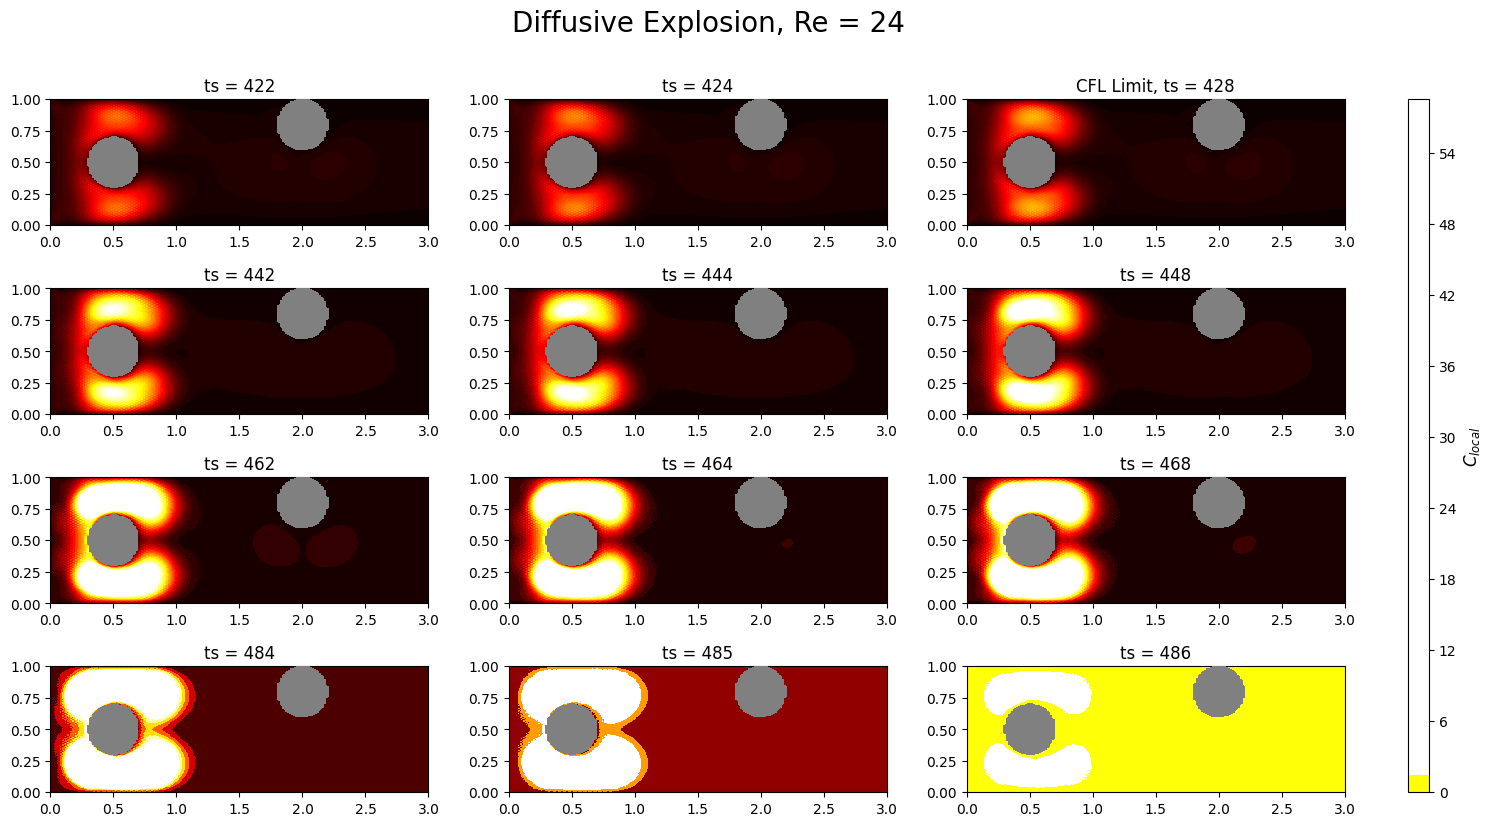

In [97]:
import matplotlib.pyplot as plt
import numpy as np

plot_steps = [422, 424, 428, 
             442, 444, 448, 
             462, 464, 468, 
             484, 485, 486]

fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(4, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.15, hspace=0.5)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 0])
ax5 = fig.add_subplot(gs[1, 1])
ax6 = fig.add_subplot(gs[1, 2])
ax7 = fig.add_subplot(gs[2, 0])
ax8 = fig.add_subplot(gs[2, 1])
ax9 = fig.add_subplot(gs[2, 2])
ax10 = fig.add_subplot(gs[3, 0])
ax11 = fig.add_subplot(gs[3, 1])
ax12 = fig.add_subplot(gs[3, 2])
cbar_ax = fig.add_subplot(gs[:, 3])

axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10, ax11, ax12]

for idx, step in enumerate(plot_steps):

    u, v = value[step]
    C_field = np.abs(u) * (dt / dx) + np.abs(v) * (dt / dy)
    
    ax = axes[idx]
    cf = ax.contourf(X, Y, C_field, levels=50, cmap='hot', vmin=0, vmax=1.0)
    ax.contourf(X, Y, obstacle, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=4)
    
    if step==428:
        ax.set_title(f'CFL Limit, ts = {step}')
    else:
        ax.set_title(f'ts = {step}')
    ax.set_aspect('equal')

cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'$C_{local}$', fontsize=12)

fig.suptitle('Diffusive Explosion, Re = 24', fontsize=20)

plt.show()


In [ ]:

Re = 765 
u_765 = []
v_765 = []

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
omega_z = np.zeros((ny, nx))
    
exploded = False
    
for n in range(nt):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)

    if np.isnan(u).any() or np.isnan(v).any():
        print(f"u exploded at ts {n}.")
        exploded = True
        break

    if not exploded:
        u_765_rn = np.max(np.abs(u))
        u_765.append(u_765_rn)
        v_765_rn = np.max(np.abs(v))
        v_765.append(v_765_rn)
    else:
        u_765.append(np.nan)
        v_765.append(np.nan)



u exploded at ts 615.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:108: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:113: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26372\988165370.py:113: RuntimeWarning: invalid value encountered in s

In [7]:
Re = 765
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
value = {}
nt_765 = 615

for n in range(nt_765):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)
    
    if n in [596, 597, 598, 
             599, 600, 601, 
             602, 603, 604, 
             605, 606, 607]:
        value[n] = (u.copy(), v.copy()) 


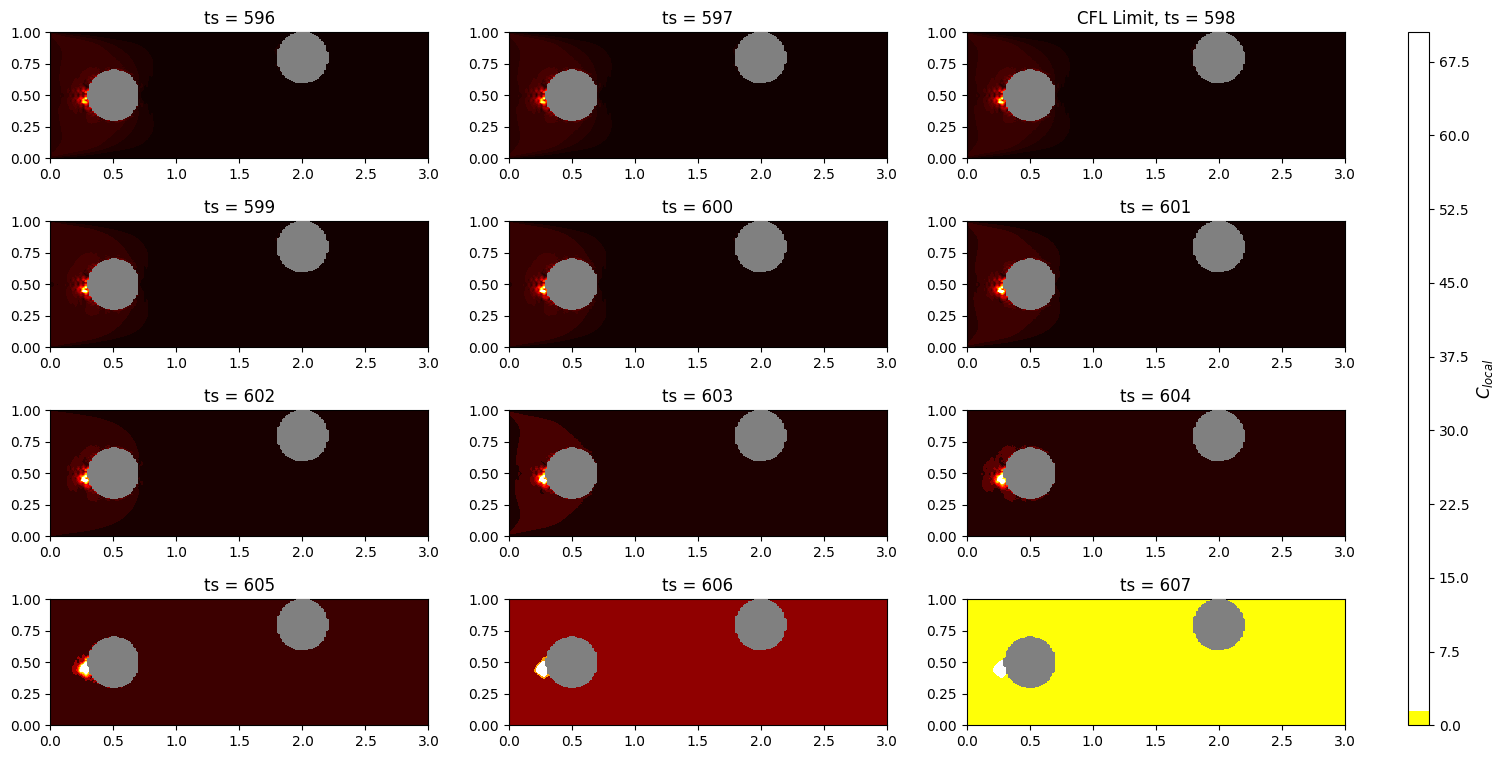

In [9]:
import matplotlib.pyplot as plt
import numpy as np

plot_steps = [596, 597, 598, 
             599, 600, 601, 
             602, 603, 604, 
             605, 606, 607]

fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(4, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.15, hspace=0.5)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 0])
ax5 = fig.add_subplot(gs[1, 1])
ax6 = fig.add_subplot(gs[1, 2])
ax7 = fig.add_subplot(gs[2, 0])
ax8 = fig.add_subplot(gs[2, 1])
ax9 = fig.add_subplot(gs[2, 2])
ax10 = fig.add_subplot(gs[3, 0])
ax11 = fig.add_subplot(gs[3, 1])
ax12 = fig.add_subplot(gs[3, 2])
cbar_ax = fig.add_subplot(gs[:, 3])

axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10, ax11, ax12]

for idx, step in enumerate(plot_steps):

    u, v = value[step]
    C_field = np.abs(u) * (dt / dx) + np.abs(v) * (dt / dy)
    
    ax = axes[idx]
    cf = ax.contourf(X, Y, C_field, levels=50, cmap='hot', vmin=0, vmax=1.0)
    ax.contourf(X, Y, obstacle, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=4)
    
    if step==598:
        ax.set_title(f'CFL Limit, ts = {step}')
    else:
        ax.set_title(f'ts = {step}')
    ax.set_aspect('equal')

cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'$C_{local}$', fontsize=12)

#fig.suptitle('Advective Explosion, Re = 765', fontsize=20)

plt.show()


In [103]:

Re = 765 
u_lim_2 = []
v_lim_2 = []

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
omega_z = np.zeros((ny, nx))

nt_lim = 617
    
exploded = False
    
for n in range(nt_lim):
    u, v = apply_velocity_bc(u, v)
    u_star, v_star = predict_velocity(u, v, dx, dy, dt, Re)
    p, omega_z = solve_pressure(p, u_star, v_star, dx, dy, dt, nit)
    u, v = correct_velocity(u_star, v_star, p, dx, dy, dt)
    u, v = apply_velocity_bc(u, v)
    
    if np.isnan(u).any() or np.isnan(v).any():
        exploded = True
        break
    if not exploded:
        if n in [590, 591, 592, 593, 594, 595, 
                 596, 597, 598, 599, 600, 601]:
            u_lim_rn = np.max(np.abs(u))
            u_lim_2.append(u_lim_rn)
            v_lim_rn = np.max(np.abs(v))
            v_lim_2.append(v_lim_rn)
    else:
        u_lim_2.append(np.nan)
        v_lim_2.append(np.nan)



C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:108: RuntimeWarning: invalid value encountered in subtract
  + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in multiply
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: overflow encountered in subtract
  + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\988165370.py:113: RuntimeWarning: invalid value encountered in s

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14880\1960697932.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


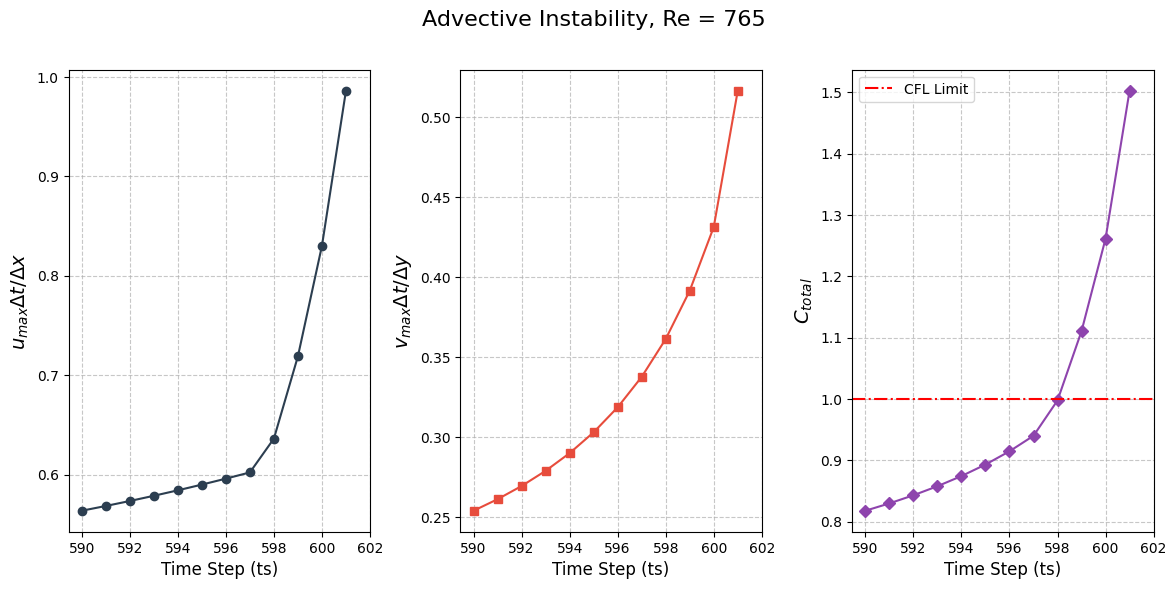

In [104]:
import matplotlib.pyplot as plt
import numpy as np

u_max_arr = np.array(u_lim_2)
v_max_arr = np.array(v_lim_2)
u_dof = u_max_arr * (dt / dx) 
v_dof = v_max_arr * (dt / dy)

ts_arr = np.arange(590, 590 + len(u_max_arr), 1) 
C = u_dof + v_dof

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 3, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

ax1.plot(ts_arr, u_max_arr * (dt / dx), marker='o', linestyle='-', color='#2c3e50')
ax1.set_xlabel('Time Step (ts)', fontsize=12)
ax1.set_ylabel(r'$u_{max} \Delta t / \Delta x$', fontsize=14)
#ax1.set_yscale('log')
ax1.grid(True, linestyle='--', alpha=0.7, which='both')

ax2.plot(ts_arr, v_max_arr * (dt / dy), marker='s', linestyle='-', color='#e74c3c')
ax2.set_xlabel('Time Step (ts)', fontsize=12)
ax2.set_ylabel(r'$v_{max} \Delta t / \Delta y$', fontsize=14)
#ax2.set_yscale('log')
ax2.grid(True, linestyle='--', alpha=0.7, which='both')

ax3.plot(ts_arr, C, marker='D', linestyle='-', color='#8e44ad')
ax3.axhline(y=1.0, color='r', linestyle='-.', label='CFL Limit')
ax3.set_xlabel('Time Step (ts)', fontsize=12)
ax3.set_ylabel(r'$C_{total}$', fontsize=14)
#ax3.set_yscale('log')
ax3.grid(True, linestyle='--', alpha=0.7, which='both')
ax3.legend()

for ax in [ax1, ax2, ax3]:
    ax.set_xticks(np.arange(590, 604, 2))
    ax.set_xticklabels([str(int(x)) for x in ax.get_xticks()]) 

fig.suptitle('Advective Instability, Re = 765', fontsize=16)
plt.tight_layout()
plt.show()